# Mission 6 — Personnalisation et recommandation
**TP Customer Intelligence & AI Marketing Strategy — cas NovaMarket**

**Objectif :** définir des règles de recommandation à partir des catégories achetées, choisir une approche (collaborative, basée sur le contenu ou hybride), prévoir le démarrage à froid et construire un **plan de personnalisation exploitable par un CRM**, avec un contrôle de la pression commerciale.

**Plan**

0. Mise en place
1. Ce que les clients achètent
2. Associations entre catégories (support, confiance, lift)
3. Trois familles de recommandation
4. Règles de recommandation retenues (approche hybride)
5. Recommandation pour chaque client
6. Démarrage à froid
7. Matrice segment × besoin × message × offre × canal
8. Contrôle de la pression commerciale
9. Export du plan pour le CRM
10. Limites

## 0. Mise en place

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/TP_NovaMarket'
except ImportError:
    BASE = os.environ.get('TP_BASE', '..')

DATA = os.path.join(BASE, 'data')
OUT = os.path.join(BASE, 'outputs')
os.makedirs(OUT, exist_ok=True)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.width', 220)
sns.set_theme(style='whitegrid')

## 1. Ce que les clients achètent

In [2]:
transactions = pd.read_csv(os.path.join(DATA, 'transactions.csv'), parse_dates=['date'])
segments = pd.read_csv(os.path.join(OUT, 'customer_segments.csv'))[['customer_id', 'segment']]
clients = pd.read_csv(os.path.join(OUT, 'customers_prepared.csv'))
churn = pd.read_csv(os.path.join(OUT, 'churn_predictions.csv'))[['customer_id', 'proba_churn', 'priorite']]
clients = clients.merge(segments, on='customer_id').merge(churn, on='customer_id')

CATEGORIES = sorted(transactions['product_category'].unique())
ventes = transactions.groupby('product_category').agg(
    transactions=('transaction_id', 'size'), CA_eur=('amount_eur', 'sum'),
    panier_moyen_eur=('amount_eur', 'mean'), clients=('customer_id', 'nunique'))
ventes['part_clients_%'] = ventes['clients'] / transactions['customer_id'].nunique() * 100
ventes.sort_values('transactions', ascending=False).round(1)

,transactions,CA_eur,panier_moyen_eur,clients,part_clients_%
product_category,,,,,
Accessoire,1161,121110.6,104.3,746,52.5
Parfum,1157,121959.2,105.4,744,52.4
Soin visage,1149,119316.7,103.8,732,51.5
Maquillage,1148,121849.0,106.1,734,51.7
Coffret,1103,115553.3,104.8,691,48.7
Soin corps,1097,112573.2,102.6,719,50.6


In [3]:
# Matrice client × catégorie : 1 si le client a déjà acheté la catégorie
achats = (pd.crosstab(transactions['customer_id'], transactions['product_category']) > 0).astype(int)
print(f'{len(achats)} clients acheteurs × {achats.shape[1]} catégories')
print('Nombre de catégories différentes achetées par client :')
achats.sum(axis=1).value_counts().sort_index().rename('clients').to_frame().T

1420 clients acheteurs × 6 catégories
Nombre de catégories différentes achetées par client :


,1,2,3,4,5,6
clients,233,332,339,228,188,100


**Constat :**
- Les 6 catégories pèsent presque autant les unes que les autres : environ 1 100 à 1 160 transactions chacune, pour un panier moyen d'environ 104 €.
- Un client achète en moyenne **3 catégories sur 6**.
- Le **potentiel de vente croisée** est réel :
    - 233 clients n'ont acheté qu'une seule catégorie ;
    - seuls 100 clients ont déjà acheté les 6.

## 2. Associations entre catégories
Pour chaque paire « A → B » :
- **Support** : part des clients qui ont acheté A **et** B.
- **Confiance** : parmi les acheteurs de A, part qui ont aussi acheté B.
- **Lift** = confiance ÷ part des clients qui achètent B. Un lift supérieur à 1 signifie qu'acheter A rend l'achat de B **plus probable que la moyenne**. Un lift de 1 signifie qu'il n'y a aucun lien.

In [4]:
part = achats.mean()
regles = []
for a in CATEGORIES:
    for b in CATEGORIES:
        if a == b:
            continue
        support = (achats[a] & achats[b]).mean()
        confiance = support / part[a]
        regles.append({'si_achat': a, 'alors_recommander': b, 'support': support,
                       'confiance': confiance, 'lift': confiance / part[b]})
regles = pd.DataFrame(regles).sort_values('lift', ascending=False)
regles.head(10).round(3)

,si_achat,alors_recommander,support,confiance,lift
8,Coffret,Soin corps,0.278,0.572,1.129
21,Soin corps,Coffret,0.278,0.549,1.129
22,Soin corps,Maquillage,0.294,0.580,1.122
13,Maquillage,Soin corps,0.294,0.568,1.122
29,Soin visage,Soin corps,0.292,0.566,1.117
24,Soin corps,Soin visage,0.292,0.576,1.117
9,Coffret,Soin visage,0.280,0.575,1.115
26,Soin visage,Coffret,0.280,0.542,1.115
11,Maquillage,Coffret,0.278,0.538,1.106
6,Coffret,Maquillage,0.278,0.572,1.106


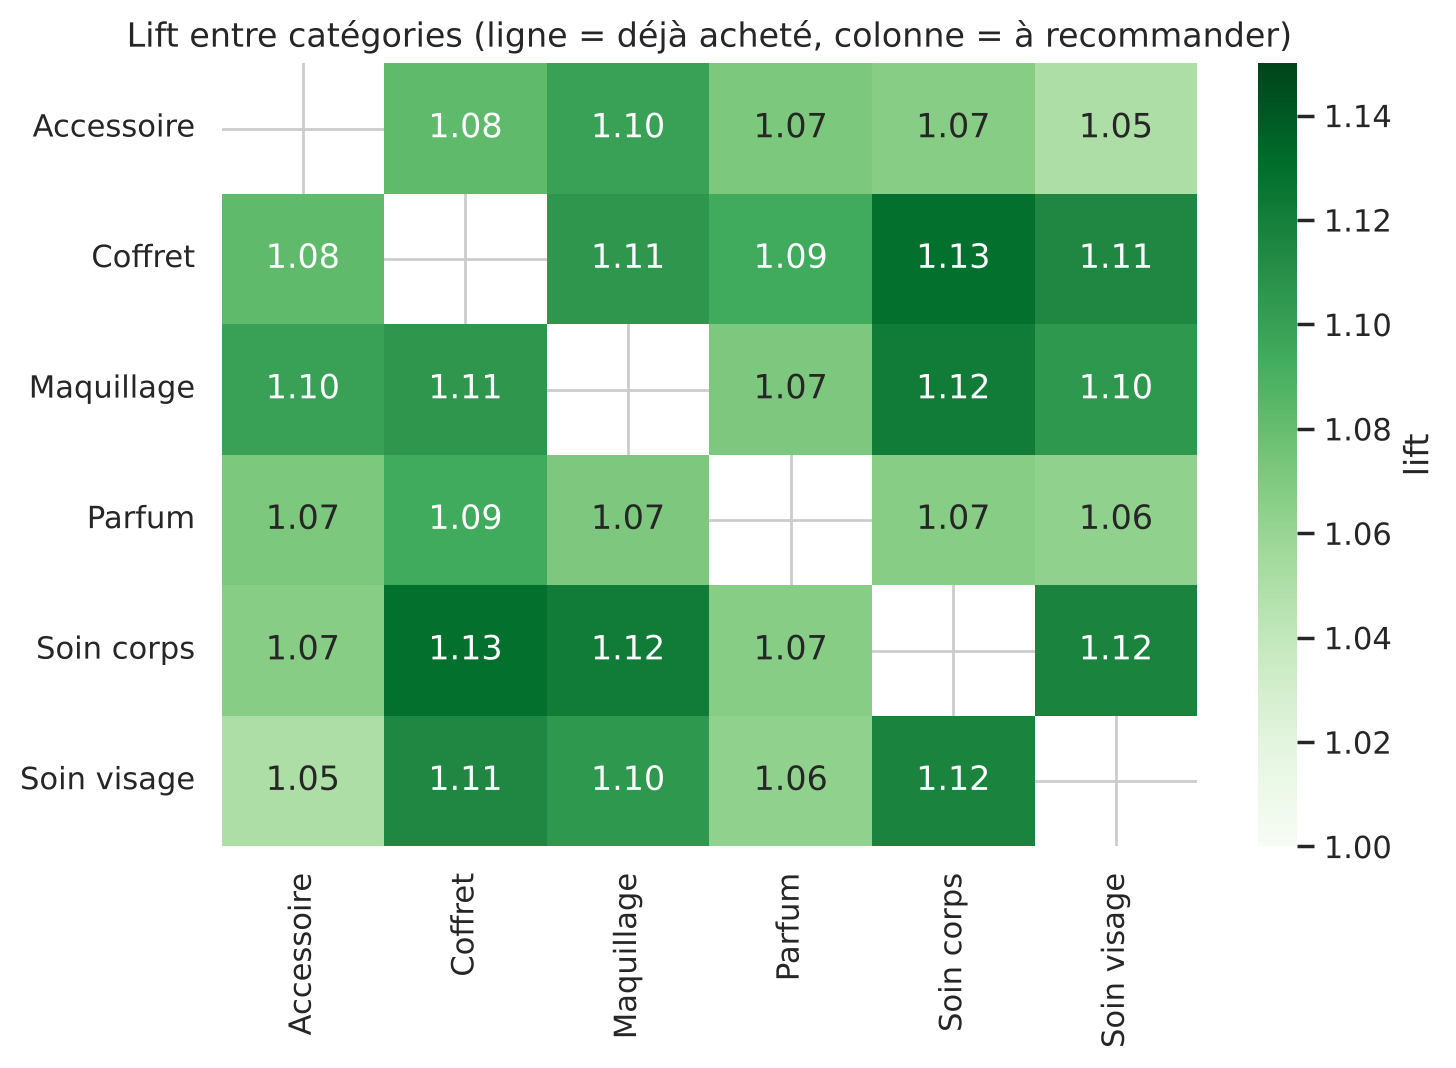

In [5]:
lift = regles.pivot(index='si_achat', columns='alors_recommander', values='lift')
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(lift, annot=True, fmt='.2f', cmap='Greens', vmin=1.0, vmax=1.15, cbar_kws={'label': 'lift'})
plt.title('Lift entre catégories (ligne = déjà acheté, colonne = à recommander)')
plt.xlabel(''); plt.ylabel('')
plt.tight_layout(); plt.show()

**Constat :**
- **Les associations les plus fortes passent toutes par le Soin corps** : Coffret ↔ Soin corps, Maquillage ↔ Soin corps et Soin visage ↔ Soin corps, avec un lift d'environ 1,12 à 1,13.
- **Tous les lifts restent modestes (entre 1,05 et 1,13).** Il y a deux raisons :
    - les **gros clients achètent de tout**, ce qui crée une association légère entre toutes les catégories ;
    - le jeu est **synthétique**, sans vraie logique de routine beauté.
- Les données seules ne suffisent donc pas à construire des recommandations fiables. Il faut les compléter par de la **connaissance métier** : c'est l'approche hybride (étape 4).

## 3. Trois familles de recommandation

| Approche | Principe | Exemple NovaMarket | Forces | Faiblesses |
|---|---|---|---|---|
| **Filtrage collaboratif** | « Les clients qui vous ressemblent ont aussi acheté… » : on s'appuie sur les comportements d'achat | Les acheteurs de Coffret achètent plus souvent du Soin corps (lift 1,13) | Découvre des associations inattendues, sans connaître les produits | Besoin de beaucoup d'historique ; impossible pour un nouveau client ou produit (démarrage à froid) ; favorise les best-sellers |
| **Basé sur le contenu** | « Ce produit ressemble à ce que vous aimez » : on s'appuie sur les caractéristiques des produits (type de peau, gamme, usage, ingrédients) | Une cliente qui achète un sérum hydratant reçoit une crème corps de la même gamme | Fonctionne dès le 1ᵉʳ achat ; recommandations explicables | Nécessite des fiches produits bien renseignées ; enferme le client dans ses habitudes |
| **Hybride** | Combine les deux, et souvent des règles métier | Règle « routine beauté » validée par le lift observé | Plus robuste, compense les faiblesses de chacun | Plus complexe à construire et à maintenir |

**Notre choix : une approche hybride simple.** Le jeu ne contient que des catégories, sans attributs produits. On combine donc :
1. le **lift observé** (partie collaborative) ;
2. des **règles de routine beauté** définies avec le métier (partie contenu).

## 4. Règles de recommandation retenues (approche hybride)
**Score d'une catégorie candidate pour un client = lift moyen avec les catégories déjà achetées + bonus de 0,05 si une règle métier la relie à l'une d'elles.**

Le bonus est volontairement faible : il départage des catégories proches sans écraser ce qu'observent les données.

In [6]:
# Règles « routine beauté » (connaissance métier) : si le client a acheté A, B est un complément naturel
REGLES_METIER = {
    ('Soin visage', 'Soin corps'): 'Compléter la routine de soin du visage au corps',
    ('Soin corps', 'Soin visage'): 'Compléter la routine de soin du corps au visage',
    ('Maquillage', 'Accessoire'): 'Pinceaux, éponges et trousses pour le maquillage',
    ('Maquillage', 'Soin visage'): 'Préparer la peau avant le maquillage',
    ('Parfum', 'Coffret'): 'Coffret parfum + soin, idée cadeau',
    ('Coffret', 'Parfum'): 'Prolonger la découverte du coffret avec le parfum',
    ('Coffret', 'Soin corps'): 'Format complet des soins découverts dans le coffret',
    ('Accessoire', 'Maquillage'): 'Produits à utiliser avec les accessoires',
}
BONUS_METIER = 0.05
pd.DataFrame([{'si_achat': a, 'recommander': b, 'raison': r,
               'lift_observe': round(lift.loc[a, b], 3)} for (a, b), r in REGLES_METIER.items()])

,si_achat,recommander,raison,lift_observe
0,Soin visage,Soin corps,Compléter la routine de soin du visage au corps,1.117
1,Soin corps,Soin visage,Compléter la routine de soin du corps au visage,1.117
2,Maquillage,Accessoire,"Pinceaux, éponges et trousses pour le maquillage",1.100
3,Maquillage,Soin visage,Préparer la peau avant le maquillage,1.105
4,Parfum,Coffret,"Coffret parfum + soin, idée cadeau",1.094
5,Coffret,Parfum,Prolonger la découverte du coffret avec le parfum,1.094
6,Coffret,Soin corps,Format complet des soins découverts dans le coffret,1.129
7,Accessoire,Maquillage,Produits à utiliser avec les accessoires,1.100


**Lecture :** toutes les règles métier ont un lift supérieur à 1. **Les données ne les contredisent pas**, et certaines sont même parmi les associations les plus fortes (Coffret → Soin corps, Soin visage → Soin corps).

## 5. Recommandation pour chaque client

In [7]:
def recommander(categories_achetees, n=2):
    """Retourne les n meilleures catégories non encore achetées, avec leur score et leur raison."""
    if len(categories_achetees) == 0:
        return []                       # nouveau client : démarrage à froid (étape 6)
    candidates = [c for c in CATEGORIES if c not in categories_achetees]
    if not candidates:
        return []                       # client qui a déjà tout acheté : réachat / nouveautés (étape 6)
    scores = []
    for b in candidates:
        score = np.mean([lift.loc[a, b] for a in categories_achetees])
        raisons = [REGLES_METIER[(a, b)] for a in categories_achetees if (a, b) in REGLES_METIER]
        if raisons:
            score += BONUS_METIER
        scores.append((b, round(float(score), 3), raisons[0] if raisons else 'Souvent achetée avec vos catégories'))
    return sorted(scores, key=lambda x: -x[1])[:n]

# Exemple
exemple = ['Soin visage', 'Maquillage']
print('Client ayant acheté', exemple, '→', recommander(exemple))

Client ayant acheté ['Soin visage', 'Maquillage'] → [('Soin corps', 1.17, 'Compléter la routine de soin du visage au corps'), ('Accessoire', 1.125, 'Pinceaux, éponges et trousses pour le maquillage')]


In [8]:
cat_par_client = achats.apply(lambda ligne: [c for c in CATEGORIES if ligne[c] == 1], axis=1)
cat_par_client = cat_par_client.reindex(clients['customer_id']).apply(lambda x: x if isinstance(x, list) else [])

# Catégorie préférée (la plus achetée) pour les clients qui ont déjà tout acheté
cat_pref = clients.set_index('customer_id')['categorie_principale']

lignes = []
for cid, achetees in cat_par_client.items():
    recos = recommander(achetees)
    if len(achetees) == 0:
        type_reco = 'Démarrage à froid'
        r1, r2, raison = 'Parfum', 'Accessoire', 'Meilleures ventes + quiz de préférences beauté'
    elif not recos:
        type_reco = 'Réachat / nouveautés'
        r1, r2, raison = cat_pref[cid], 'Nouveautés', 'A déjà acheté toutes les catégories : réassort et nouveautés'
    else:
        type_reco = 'Vente croisée'
        r1 = recos[0][0]
        r2 = recos[1][0] if len(recos) > 1 else 'Nouveautés'
        raison = recos[0][2]
    lignes.append({'customer_id': cid, 'nb_categories_achetees': len(achetees),
                   'categories_achetees': ' | '.join(achetees), 'type_reco': type_reco,
                   'categorie_reco_1': r1, 'categorie_reco_2': r2, 'raison_reco': raison})
recos = pd.DataFrame(lignes)
recos['type_reco'].value_counts().to_frame('clients')

,clients
type_reco,
Vente croisée,1320
Réachat / nouveautés,100
Démarrage à froid,80


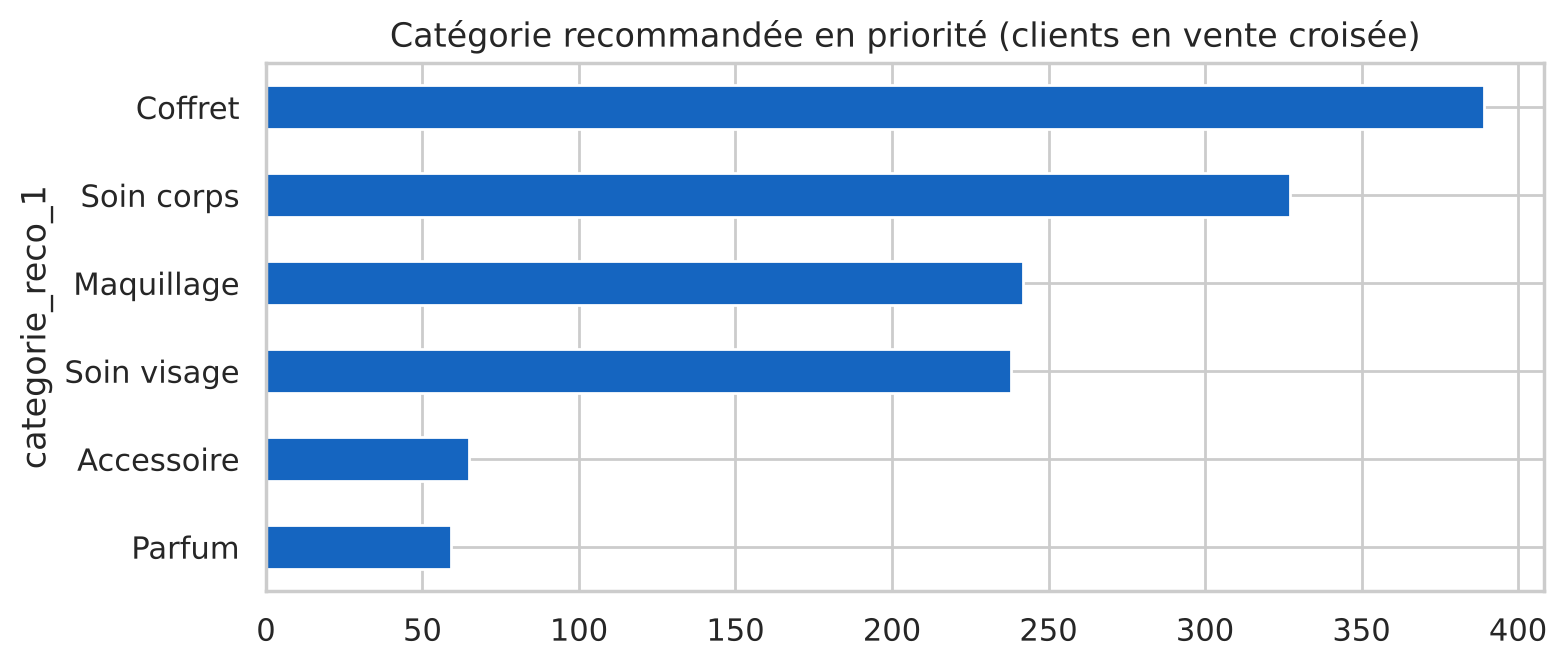

,customer_id,nb_categories_achetees,categories_achetees,type_reco,categorie_reco_1,categorie_reco_2,raison_reco
1116,C01117,5,Accessoire | Coffret | Maquillage | Soin corps | Soin visage,Vente croisée,Parfum,Nouveautés,Prolonger la découverte du coffret avec le parfum
1368,C01369,3,Parfum | Soin corps | Soin visage,Vente croisée,Coffret,Maquillage,"Coffret parfum + soin, idée cadeau"
422,C00423,5,Accessoire | Coffret | Maquillage | Parfum | Soin visage,Vente croisée,Soin corps,Nouveautés,Format complet des soins découverts dans le coffret
413,C00414,2,Coffret | Maquillage,Vente croisée,Soin corps,Soin visage,Format complet des soins découverts dans le coffret
451,C00452,0,,Démarrage à froid,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté
861,C00862,2,Parfum | Soin corps,Vente croisée,Coffret,Soin visage,"Coffret parfum + soin, idée cadeau"
1063,C01064,2,Maquillage | Parfum,Vente croisée,Coffret,Accessoire,"Coffret parfum + soin, idée cadeau"
741,C00742,3,Parfum | Soin corps | Soin visage,Vente croisée,Coffret,Maquillage,"Coffret parfum + soin, idée cadeau"


In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
recos.loc[recos['type_reco'] == 'Vente croisée', 'categorie_reco_1'].value_counts().sort_values().plot.barh(ax=ax, color='#1565C0')
ax.set_title('Catégorie recommandée en priorité (clients en vente croisée)')
plt.tight_layout(); plt.show()
recos.sample(8, random_state=RANDOM_STATE)

**Lecture :**
- **Le Coffret et le Soin corps sont les catégories les plus recommandées** (environ 390 et 330 clients). Ce sont les deux catégories les **moins achetées** de la base, ce qui en fait un vrai relais de croissance. Elles ont aussi les associations les plus fortes et sont reliées par des règles métier.
- C'est une base pour deux campagnes de vente croisée :
    - **« Routine complète »** autour du Soin corps ;
    - **« Coffret découverte »**, qui fait aussi une bonne idée cadeau.
- Le Parfum et l'Accessoire, déjà achetés par plus de la moitié des clients, sont rarement recommandés.

## 6. Démarrage à froid
Le filtrage collaboratif ne sait rien recommander à un client **sans historique**. Il y a deux cas dans la base :

| Cas | Clients | Stratégie |
|---|---|---|
| **Nouveaux sans commande** (segment « Nouveaux à activer ») | 80 | 1) **Meilleures ventes** (Parfum, Accessoire : catégories les plus achetées) ; 2) **quiz beauté** à l'inscription (type de peau, routine, budget) pour basculer vers des recommandations basées sur le contenu ; 3) **canal d'acquisition** : un client venu par Instagram reçoit les produits mis en avant sur Instagram |
| **Clients ayant déjà tout acheté** | environ 100 | Pas de nouvelle catégorie à proposer : **réassort** de la catégorie préférée au moment habituel de rachat + **nouveautés** en avant-première |
| **Nouveau produit** (sans historique de vente) | — | Recommandé par ses **attributs** (approche contenu) aux acheteurs de produits similaires, et mis en avant dans les contenus « nouveautés » |

Dès le 1ᵉʳ achat, le client sort du démarrage à froid et entre dans la logique de vente croisée.

## 7. Matrice segment × besoin × message × offre × canal
Construite à partir des segments (mission 3), des risques de churn (mission 4), des irritants (mission 5) et des recommandations ci-dessus.

In [10]:
matrice = pd.DataFrame([
    {'segment': 'Fidèles premium',
     'constat': '16 % des clients, 54 % du CA, churn 4 %, satisfaction 4,6',
     'besoin': 'Être reconnus, découvrir en premier',
     'message': 'Vous faites partie de nos meilleurs clients : découvrez nos nouveautés avant tout le monde',
     'offre': 'Avant-première nouveautés + cadeau surprise (pas de remise)',
     'canal': 'Email personnalisé + Instagram (contenus exclusifs)',
     'frequence_max': '1 message / semaine',
     'objectif': 'O1 rétention', 'kpi': 'Rétention du segment, CA par client, nombre de parrainages'},
    {'segment': 'Réguliers satisfaits',
     'constat': '34 % des clients, environ 5 commandes/an, satisfaction 4,1',
     'besoin': 'Compléter leur routine, être récompensés',
     'message': 'Votre routine mérite son complément : [catégorie recommandée] sélectionné pour vous',
     'offre': 'Points de fidélité doublés sur la catégorie recommandée',
     'canal': 'Email + bloc de recommandations sur le site',
     'frequence_max': '1 message / semaine',
     'objectif': 'O2 réachat', 'kpi': 'Commandes par client, nombre de catégories achetées, panier moyen'},
    {'segment': 'Occasionnels récents',
     'constat': '18 % des clients, environ 2 commandes, achat récent, satisfaits',
     'besoin': 'Une raison de revenir rapidement',
     'message': 'Vous avez aimé [catégorie achetée] ? Essayez [catégorie recommandée], livraison offerte',
     'offre': 'Livraison offerte sur la 2ᵉ ou 3ᵉ commande, valable 30 jours',
     'canal': 'Email automatique J+30 après l\'achat + retargeting Instagram',
     'frequence_max': '2 messages / mois',
     'objectif': 'O2 réachat', 'kpi': 'Taux de réachat à 60 jours'},
    {'segment': 'En décrochage',
     'constat': '26 % des clients, churn 66 %, satisfaction 2,7, environ 2 tickets support',
     'besoin': 'Que leur problème soit réglé avant toute promotion',
     'message': 'Votre avis compte : dites-nous ce qui n\'a pas fonctionné, nous voulons le corriger',
     'offre': 'P1 : appel + offre personnalisée / P2 : bon de 10 € / P3 : email de réactivation (mission 4)',
     'canal': 'Service client (P1), email automatisé (P2-P3)',
     'frequence_max': '1 message / 2 semaines',
     'objectif': 'O1 rétention', 'kpi': 'Taux de churn, satisfaction après contact, CA récupéré'},
    {'segment': 'Nouveaux à activer',
     'constat': '80 clients, contact récent, pas de commande sur 12 mois',
     'besoin': 'Être guidés pour un premier achat réussi',
     'message': 'Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté',
     'offre': 'Échantillons offerts avec la 1ʳᵉ commande',
     'canal': 'Série d\'emails de bienvenue (J0, J3, J10) + site',
     'frequence_max': '3 messages sur 15 jours, puis 1 / semaine',
     'objectif': 'O2 réachat', 'kpi': 'Taux de 1ʳᵉ commande, puis taux de 2ᵉ commande'},
])
matrice.to_csv(os.path.join(OUT, 'personalization_matrix.csv'), index=False)
matrice.set_index('segment').T

segment,Fidèles premium,Réguliers satisfaits,Occasionnels récents,En décrochage,Nouveaux à activer
constat,"16 % des clients, 54 % du CA, churn 4 %, satisfaction 4,6","34 % des clients, environ 5 commandes/an, satisfaction 4,1","18 % des clients, environ 2 commandes, achat récent, satisfaits","26 % des clients, churn 66 %, satisfaction 2,7, environ 2 tickets ...","80 clients, contact récent, pas de commande sur 12 mois"
besoin,"Être reconnus, découvrir en premier","Compléter leur routine, être récompensés",Une raison de revenir rapidement,Que leur problème soit réglé avant toute promotion,Être guidés pour un premier achat réussi
message,Vous faites partie de nos meilleurs clients : découvrez nos nouvea...,Votre routine mérite son complément : [catégorie recommandée] séle...,Vous avez aimé [catégorie achetée] ? Essayez [catégorie recommandé...,"Votre avis compte : dites-nous ce qui n'a pas fonctionné, nous vou...",Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté
offre,Avant-première nouveautés + cadeau surprise (pas de remise),Points de fidélité doublés sur la catégorie recommandée,"Livraison offerte sur la 2ᵉ ou 3ᵉ commande, valable 30 jours",P1 : appel + offre personnalisée / P2 : bon de 10 € / P3 : email d...,Échantillons offerts avec la 1ʳᵉ commande
canal,Email personnalisé + Instagram (contenus exclusifs),Email + bloc de recommandations sur le site,Email automatique J+30 après l'achat + retargeting Instagram,"Service client (P1), email automatisé (P2-P3)","Série d'emails de bienvenue (J0, J3, J10) + site"
frequence_max,1 message / semaine,1 message / semaine,2 messages / mois,1 message / 2 semaines,"3 messages sur 15 jours, puis 1 / semaine"
objectif,O1 rétention,O2 réachat,O2 réachat,O1 rétention,O2 réachat
kpi,"Rétention du segment, CA par client, nombre de parrainages","Commandes par client, nombre de catégories achetées, panier moyen",Taux de réachat à 60 jours,"Taux de churn, satisfaction après contact, CA récupéré","Taux de 1ʳᵉ commande, puis taux de 2ᵉ commande"


**Points clés :**
- **Pas de remise pour les Fidèles premium.** Ils achètent déjà : une réduction réduirait la marge sans changer leur comportement. On mise sur la **reconnaissance**.
- **Le service avant la promotion pour les clients En décrochage.** La mission 5 montre que les irritants sont la commande incomplète, la livraison, la qualité et le site : une remise ne règle pas un colis incomplet.
- **Le message reprend la catégorie recommandée** de l'étape 5. Ce champ est rempli automatiquement par le CRM.

## 8. Contrôle de la pression commerciale
Personnaliser ne veut pas dire envoyer plus de messages. Les règles suivantes s'appliquent **avant** tout envoi :

| Règle | Détail |
|---|---|
| **Un seul scénario actif par client** | Priorité : 1) rétention P1/P2/P3 (mission 4), 2) bienvenue des nouveaux, 3) vente croisée, 4) fidélisation premium |
| **Plafond de fréquence** | Au maximum la fréquence indiquée dans la matrice, et **jamais plus de 4 messages marketing par mois**, tous canaux confondus |
| **Exclusions temporaires** | Ticket support ouvert, avis négatif récent ou commande en cours de livraison : pas de message promotionnel, seulement du service |
| **Fatigue** | 3 emails non ouverts d'affilée : fréquence divisée par deux ; 6 : pause de 30 jours |
| **Consentement** | Uniquement les clients ayant accepté l'emailing marketing, avec un lien de désinscription dans chaque message |
| **Groupe témoin** | 10 % des clients de chaque segment, tirés au hasard, ne reçoivent pas le scénario, pour mesurer l'effet réel |

In [11]:
# Attribution du scénario unique et du groupe témoin
def scenario(ligne):
    if ligne['priorite'] in ('P1', 'P2', 'P3'):
        return f"Rétention {ligne['priorite']}"
    if ligne['segment'] == 'Nouveaux à activer':
        return 'Bienvenue / démarrage à froid'
    if ligne['segment'] == 'Fidèles premium':
        return 'Fidélisation premium'
    return 'Vente croisée'

plan = clients[['customer_id', 'segment', 'proba_churn', 'priorite', 'taux_clic_email',
                'part_achats_mobile', 'support_tickets_90d']].merge(recos, on='customer_id')
plan['scenario'] = plan.apply(scenario, axis=1)

rng = np.random.default_rng(RANDOM_STATE)
plan['groupe_temoin'] = (plan.groupby('segment')['customer_id'].transform(lambda s: rng.random(len(s))) < 0.10).astype(int)

# Canal préféré : email si le client clique, sinon SMS / push s'il achète surtout sur mobile, sinon email + retargeting
plan['canal_prefere'] = np.select(
    [plan['taux_clic_email'] >= 0.2, plan['part_achats_mobile'] >= 0.5],
    ['Email', 'SMS / notification mobile'], default='Email + retargeting')
plan['exclusion_promo_temporaire'] = (plan['support_tickets_90d'] >= 3).astype(int)

pd.crosstab(plan['segment'], plan['scenario'])

scenario,Bienvenue / démarrage à froid,Fidélisation premium,Rétention P1,Rétention P2,Rétention P3,Vente croisée
segment,,,,,,
En décrochage,0,0,40,249,79,26
Fidèles premium,0,236,0,0,0,0
Nouveaux à activer,77,0,0,0,3,0
Occasionnels récents,0,0,0,0,20,254
Réguliers satisfaits,0,0,1,3,54,458


In [12]:
print(f"Groupe témoin : {plan['groupe_temoin'].sum()} clients ({plan['groupe_temoin'].mean():.0%})")
print(f"Clients exclus temporairement des promotions (3 tickets ou plus) : {plan['exclusion_promo_temporaire'].sum()}")
plan['canal_prefere'].value_counts().to_frame('clients')

Groupe témoin : 145 clients (10%)
Clients exclus temporairement des promotions (3 tickets ou plus) : 130


,clients
canal_prefere,
Email,616
Email + retargeting,584
SMS / notification mobile,300


## 9. Export du plan pour le CRM

In [13]:
plan = plan.merge(matrice[['segment', 'message', 'offre', 'frequence_max']], on='segment', how='left')
colonnes = ['customer_id', 'segment', 'scenario', 'priorite', 'proba_churn', 'type_reco',
            'categories_achetees', 'categorie_reco_1', 'categorie_reco_2', 'raison_reco',
            'message', 'offre', 'canal_prefere', 'frequence_max', 'exclusion_promo_temporaire', 'groupe_temoin']
plan_crm = plan[colonnes].sort_values(['scenario', 'proba_churn'], ascending=[True, False])
plan_crm.to_csv(os.path.join(OUT, 'personalization_plan_crm.csv'), index=False)
print('personalization_plan_crm.csv :', plan_crm.shape)
plan_crm.head(8)

personalization_plan_crm.csv : (1500, 16)


,customer_id,segment,scenario,priorite,proba_churn,type_reco,categories_achetees,categorie_reco_1,categorie_reco_2,raison_reco,message,offre,canal_prefere,frequence_max,exclusion_promo_temporaire,groupe_temoin
278,C00279,Nouveaux à activer,Bienvenue / démarrage à froid,Aucune,0.1945,Démarrage à froid,,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté,Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté,Échantillons offerts avec la 1ʳᵉ commande,Email + retargeting,"3 messages sur 15 jours, puis 1 / semaine",1,1
151,C00152,Nouveaux à activer,Bienvenue / démarrage à froid,Aucune,0.1798,Démarrage à froid,,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté,Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté,Échantillons offerts avec la 1ʳᵉ commande,Email + retargeting,"3 messages sur 15 jours, puis 1 / semaine",0,0
598,C00599,Nouveaux à activer,Bienvenue / démarrage à froid,Aucune,0.1704,Démarrage à froid,,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté,Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté,Échantillons offerts avec la 1ʳᵉ commande,Email + retargeting,"3 messages sur 15 jours, puis 1 / semaine",0,0
23,C00024,Nouveaux à activer,Bienvenue / démarrage à froid,Aucune,0.1702,Démarrage à froid,,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté,Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté,Échantillons offerts avec la 1ʳᵉ commande,Email + retargeting,"3 messages sur 15 jours, puis 1 / semaine",0,0
5,C00006,Nouveaux à activer,Bienvenue / démarrage à froid,Aucune,0.1699,Démarrage à froid,,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté,Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté,Échantillons offerts avec la 1ʳᵉ commande,Email + retargeting,"3 messages sur 15 jours, puis 1 / semaine",0,0
915,C00916,Nouveaux à activer,Bienvenue / démarrage à froid,Aucune,0.1608,Démarrage à froid,,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté,Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté,Échantillons offerts avec la 1ʳᵉ commande,Email + retargeting,"3 messages sur 15 jours, puis 1 / semaine",1,0
526,C00527,Nouveaux à activer,Bienvenue / démarrage à froid,Aucune,0.1493,Démarrage à froid,,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté,Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté,Échantillons offerts avec la 1ʳᵉ commande,Email + retargeting,"3 messages sur 15 jours, puis 1 / semaine",0,1
613,C00614,Nouveaux à activer,Bienvenue / démarrage à froid,Aucune,0.1471,Démarrage à froid,,Parfum,Accessoire,Meilleures ventes + quiz de préférences beauté,Bienvenue ! Trouvez votre routine en 2 minutes avec notre quiz beauté,Échantillons offerts avec la 1ʳᵉ commande,Email + retargeting,"3 messages sur 15 jours, puis 1 / semaine",0,0


**Fichiers produits dans `outputs/` :**
- `personalization_plan_crm.csv` : pour chaque client, son scénario, les catégories recommandées, le message, l'offre, le canal, la fréquence maximale, une éventuelle exclusion temporaire et son appartenance au groupe témoin. C'est un fichier **importable dans un CRM**.
- `personalization_matrix.csv` : la matrice segment × besoin × message × offre × canal.

## 10. Limites
- **Recommandation au niveau de la catégorie seulement** : le jeu ne contient ni produits ni attributs (type de peau, gamme, prix). Une vraie approche basée sur le contenu nécessite un **catalogue enrichi**.
- **Associations faibles** (lift ≤ 1,13), en partie expliquées par la taille des clients : les gros acheteurs achètent de tout. Il faudrait comparer les clients à profil d'achat équivalent ou utiliser l'**ordre des achats** (ce qui est acheté *après*).
- **Règles métier subjectives** : elles doivent être validées par l'équipe produit, puis **testées en A/B** (règle hybride contre meilleures ventes) avant d'être généralisées.
- **Biais de popularité** : les recommandations tendent à pousser les catégories déjà les plus vendues.
- **Risque de sur-sollicitation et de « bulle »** : sans les règles de pression commerciale, la personnalisation peut agacer. Elle peut aussi enfermer le client dans ce qu'il connaît : il faut prévoir une part de découverte (nouveautés).
- **RGPD** : la personnalisation repose sur du **profilage**. Il faut informer les clients, respecter leur consentement et leur droit d'opposition.